# 03 - Explainable AI with SHAP
A model that is accurate but opaque is hard to trust, especially for farmers and policy makers. **SHAP** (SHapley Additive exPlanations) assigns each feature a contribution to each prediction so that

`prediction = base value (average prediction) + sum of feature contributions`.

We use `TreeExplainer`, an exact and fast algorithm for tree models. Because a country becomes ~100 one-hot columns, we **sum the one-hot SHAP values back to the original feature** (valid because SHAP is additive) so plots read "Crop = Potatoes" rather than 100 dummy columns.

In [1]:
import sys; sys.path.append("..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Markdown, display, Image
from src import config as C
from src.explain_global import load_global_explainer
from src.explain import pick_examples
ex, test, meta = load_global_explainer()
X = test[C.G_FEATURES]; sample = X.sample(1500, random_state=C.RANDOM_STATE)
print("Explaining:", meta["best_name"], "| base value (average prediction):", round(ex.base_value))

Explaining: XGBoost (tuned) | base value (average prediction): 74524


## 1. Global importance

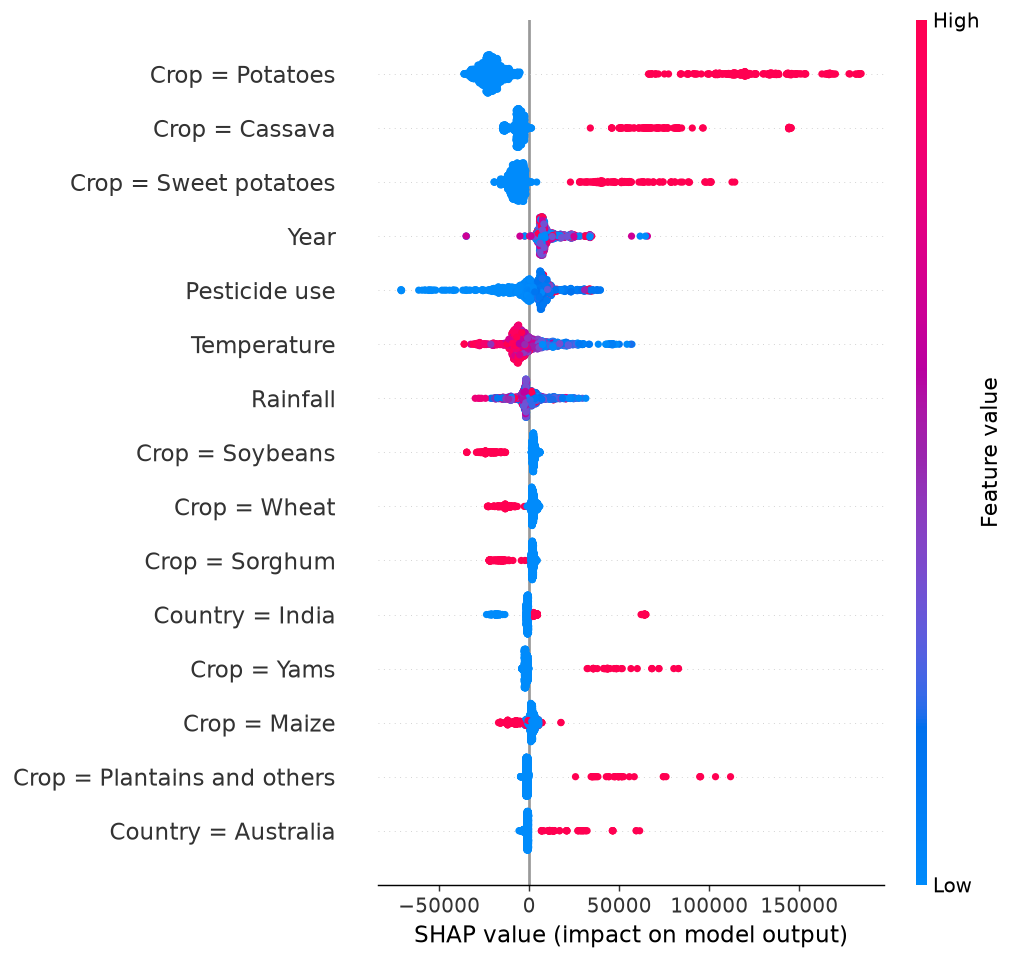

In [2]:
ex.beeswarm(sample, C.FIG_DIR / "shap_beeswarm.png"); display(Image(str(C.FIG_DIR / "shap_beeswarm.png")))

**Beeswarm:** each dot is one prediction; position = push on predicted yield (right = increases), colour = feature value (red high, blue low; for one-hot columns, red = 'this category'). The crop dummies (potatoes, cassava...) have by far the widest spread.

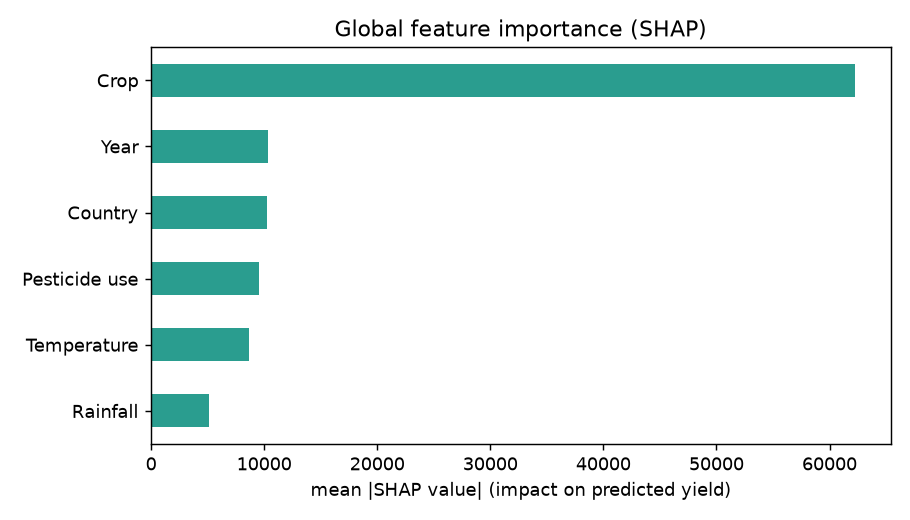

,% of total |SHAP|
Crop,58.7
Year,9.7
Country,9.7
Pesticide use,9.0
Temperature,8.1
Rainfall,4.8


In [3]:
ex.bar_plot(sample, C.FIG_DIR / "shap_bar.png"); display(Image(str(C.FIG_DIR / "shap_bar.png")))
imp = ex.mean_abs_grouped(sample); imp.index = [C.G_LABELS[i] for i in imp.index]; display((imp/imp.sum()*100).round(1).to_frame("% of total |SHAP|"))

## 2. SHAP vs the model's built-in feature importance

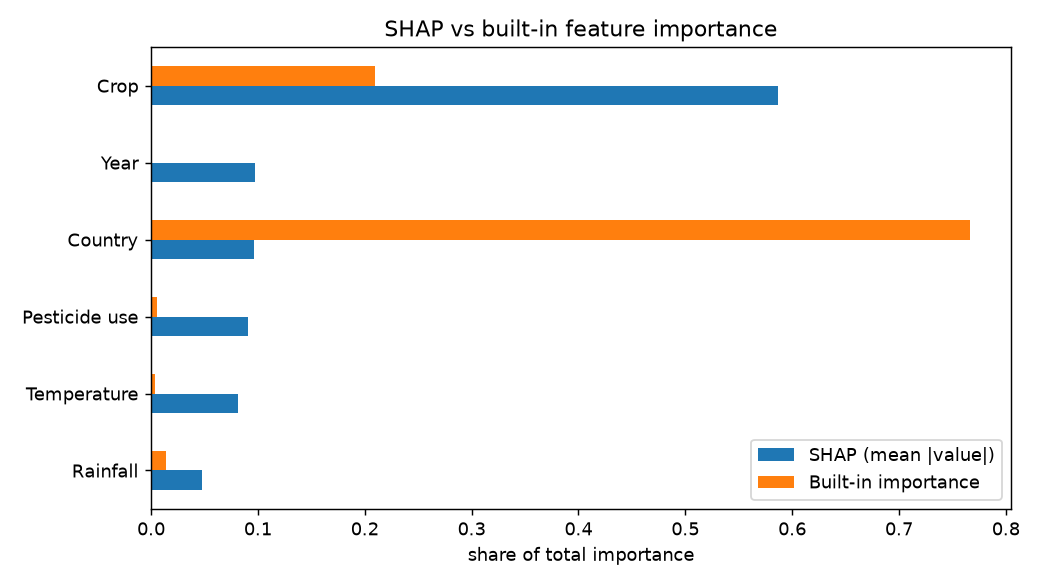

,SHAP (mean |value|),Built-in importance
Crop,58.7,21.000000
Year,9.7,0.100000
Country,9.7,76.699997
Pesticide use,9.0,0.500000
Temperature,8.1,0.300000
Rainfall,4.8,1.400000


In [4]:
cmp = ex.compare_importance(sample, C.FIG_DIR / "shap_vs_builtin.png"); display(Image(str(C.FIG_DIR / "shap_vs_builtin.png"))); display((cmp*100).round(1))

In [5]:
display(Markdown(f'''**Interpretation.** The two rankings disagree. Built-in (split-gain) importance credits **Country** with {cmp.loc["Country","Built-in importance"]*100:.0f}% and gives weather almost nothing, while SHAP says **Crop** is the most influential ({cmp.loc["Crop","SHAP (mean |value|)"]*100:.0f}%) and gives Year, Pesticide use, Temperature and Rainfall a meaningful share. Why? Built-in importance is *summed over ~100 country dummy columns*, which inflates it and it is computed on training data; SHAP measures the actual effect on predictions on held-out rows. This is a good reason to prefer SHAP for explanation.'''))

**Interpretation.** The two rankings disagree. Built-in (split-gain) importance credits **Country** with 77% and gives weather almost nothing, while SHAP says **Crop** is the most influential (59%) and gives Year, Pesticide use, Temperature and Rainfall a meaningful share. Why? Built-in importance is *summed over ~100 country dummy columns*, which inflates it and it is computed on training data; SHAP measures the actual effect on predictions on held-out rows. This is a good reason to prefer SHAP for explanation.

## 3. Dependence plots - how does yield respond to rainfall, temperature, pesticides?

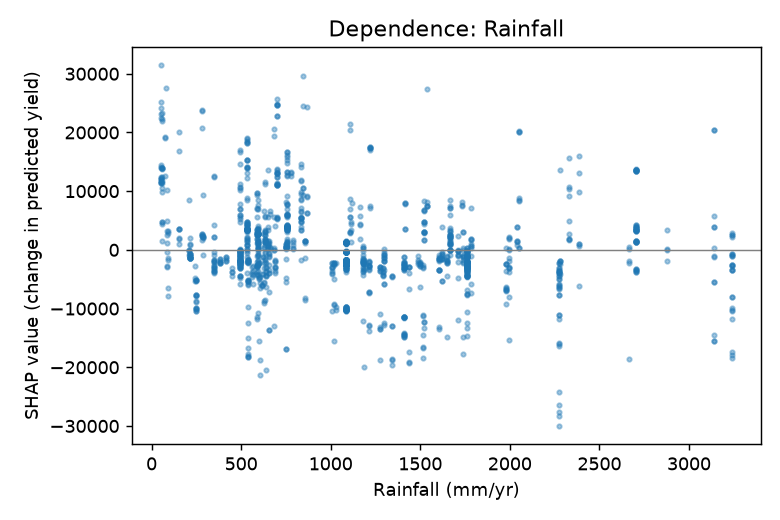

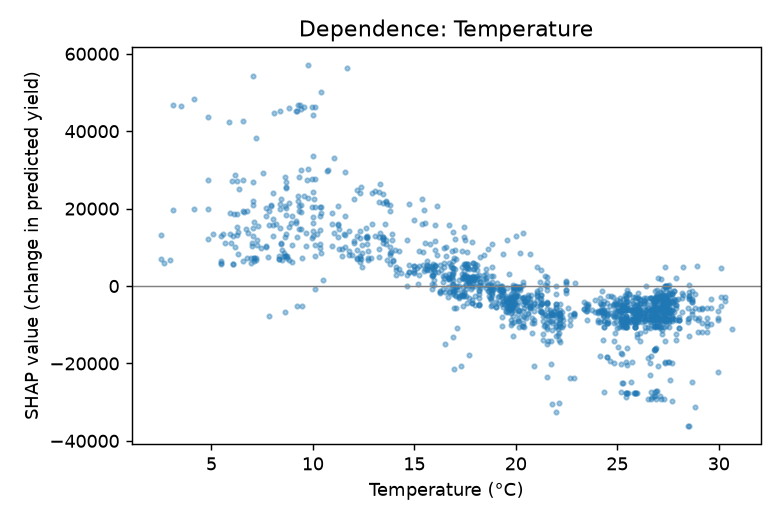

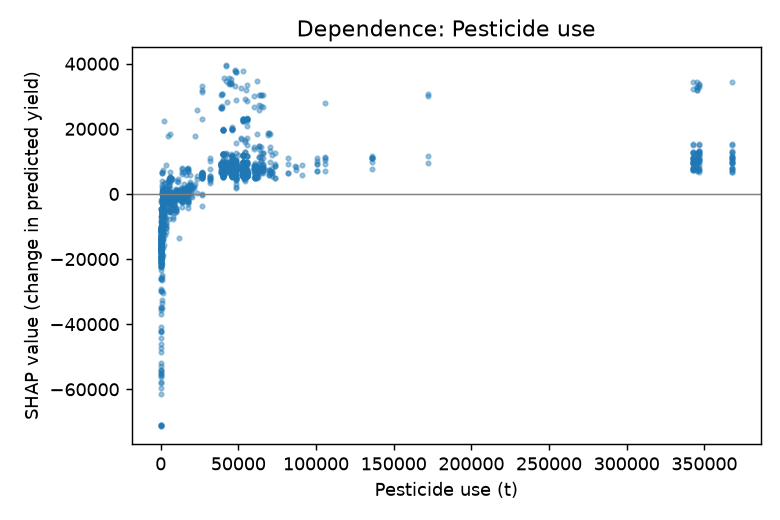

In [6]:
for col, nm in [(C.G_RAIN, "rainfall"), (C.G_TEMP, "temperature"), (C.G_PEST, "pesticides")]:
    ex.dependence(sample, col, C.FIG_DIR / f"shap_dependence_{nm}.png"); display(Image(str(C.FIG_DIR / f"shap_dependence_{nm}.png")))

**Reading these:** each dot is a prediction; height is how much that feature moved the predicted yield. The *vertical spread at the same x* appears because the effect depends on crop and country (interactions). Patterns reflect **associations learned from data, not causal effects** - e.g. high pesticide totals mostly mark big, intensive agricultural countries.

## 4. Local explanations - three predictions (high / medium / low)

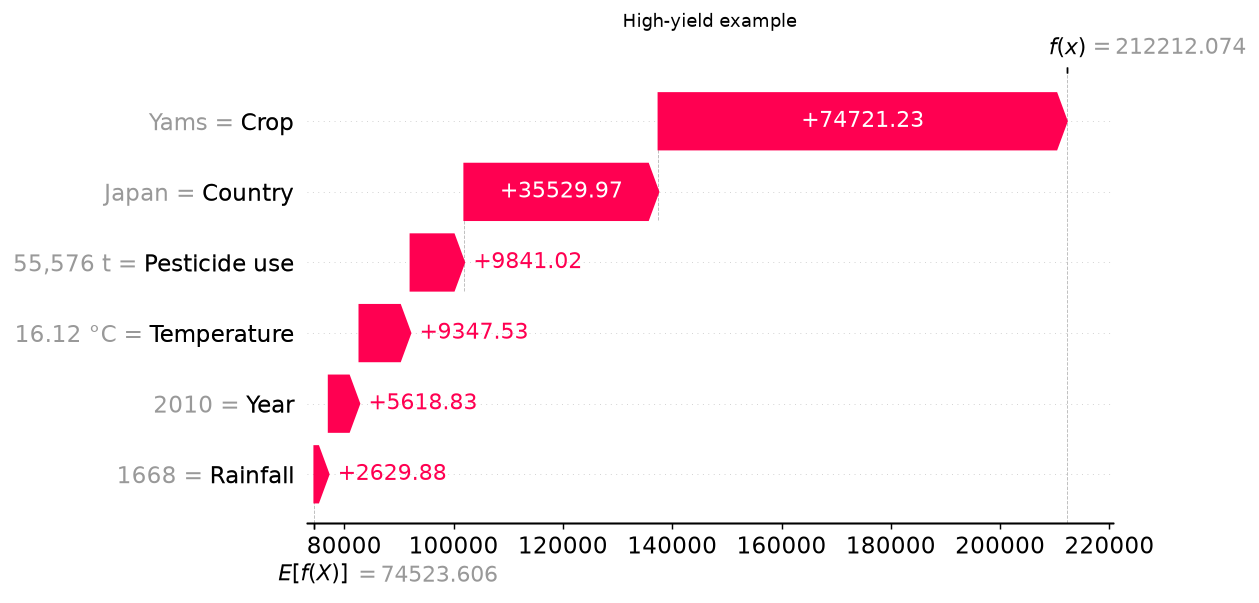

**HIGH** - actual: 226,963 hg/ha (Yams, Japan, 2010).  
The model predicts 212,212 hg/ha (average prediction: 74,524). Crop 'Yams' increased the predicted yield by 74,721 hg/ha; Country 'Japan' increased the predicted yield by 35,530 hg/ha; High pesticide use (55,576 t) increased the predicted yield by 9,841 hg/ha.

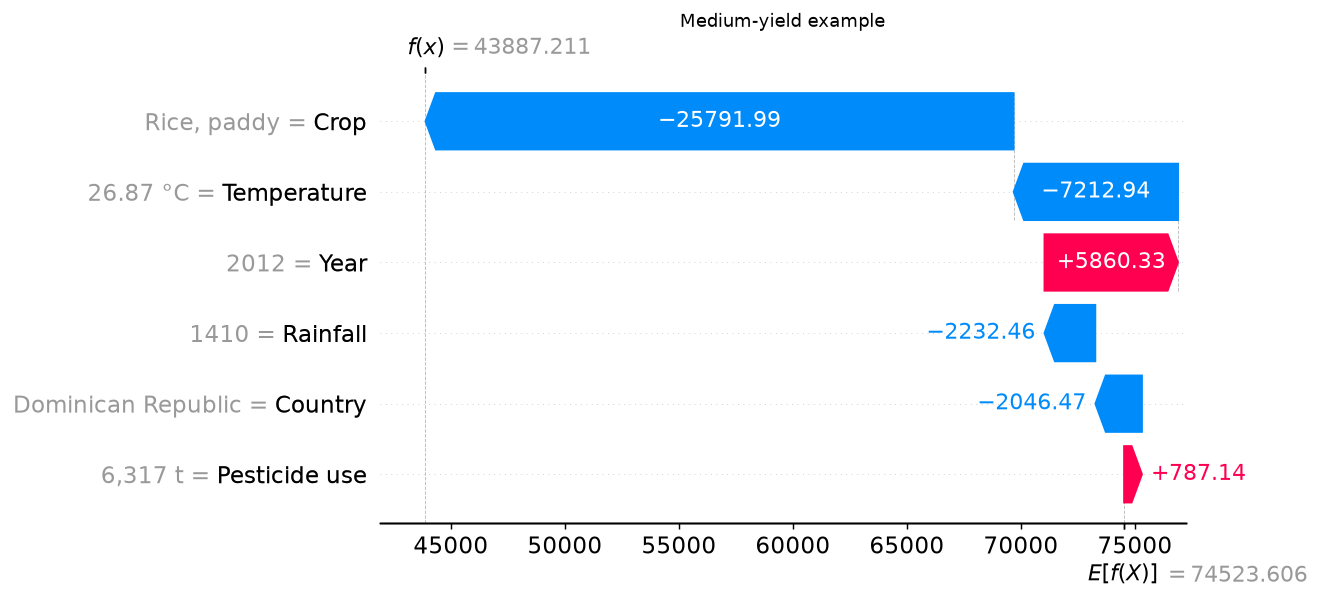

**MEDIUM** - actual: 41,266 hg/ha (Rice, paddy, Dominican Republic, 2012).  
The model predicts 43,887 hg/ha (average prediction: 74,524). Crop 'Rice, paddy' reduced the predicted yield by 25,792 hg/ha; High temperature (26.87 °C) reduced the predicted yield by 7,213 hg/ha; Year (2012) increased the predicted yield by 5,860 hg/ha.

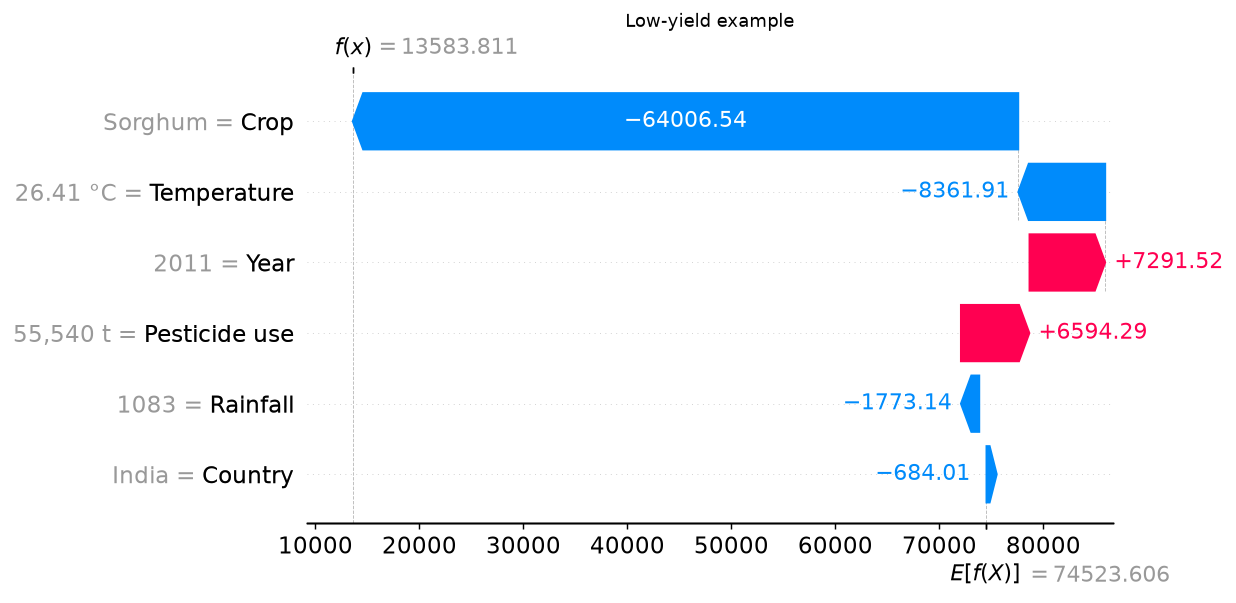

**LOW** - actual: 9,487 hg/ha (Sorghum, India, 2011).  
The model predicts 13,584 hg/ha (average prediction: 74,524). Crop 'Sorghum' reduced the predicted yield by 64,007 hg/ha; High temperature (26.41 °C) reduced the predicted yield by 8,362 hg/ha; Year (2011) increased the predicted yield by 7,292 hg/ha.

In [7]:
pred = ex.fitted.predict(X); ex_idx = pick_examples(pred); texts = {}
for name, i in ex_idx.items():
    row = X.iloc[[i]]
    ex.waterfall(row, C.FIG_DIR / f"shap_waterfall_{name}.png", title=f"{name.capitalize()}-yield example")
    display(Image(str(C.FIG_DIR / f"shap_waterfall_{name}.png")))
    r = test.iloc[i]; texts[name] = ex.sentence(row)
    display(Markdown(f"**{name.upper()}** - actual: {r[C.G_TARGET]:,.0f} hg/ha ({r[C.G_CROP]}, {r[C.G_COUNTRY]}, {int(r[C.G_YEAR])}).  \n{texts[name]}"))

**How to read a waterfall:** it starts at the average prediction (E[f(X)] at the bottom), each bar adds (red) or subtracts (blue) a feature's contribution, and ends at this prediction f(x) at the top. The three examples show that the **crop** sets the scale of the prediction, while country, climate and pesticide levels fine-tune it.

## 5. Plain-English explanation function
`Explainer.sentence()` turns the top-3 contributions into a sentence (low/typical/high is judged against the dataset's 33rd/67th percentile). It is what the Streamlit app shows to users.

In [8]:
row = X.iloc[[ex_idx["medium"]]].copy(); row[C.G_RAIN] = 300.0
print("What if rainfall were only 300 mm?\n", ex.sentence(row))

What if rainfall were only 300 mm?
 The model predicts 41,174 hg/ha (average prediction: 74,524). Crop 'Rice, paddy' reduced the predicted yield by 30,682 hg/ha; Year (2012) increased the predicted yield by 6,415 hg/ha; High temperature (26.87 °C) reduced the predicted yield by 4,000 hg/ha.
